<span style="font-size:2em;">Instructor: Dr. Qipei (Gavin) Mei (qipei.mei@ualberta.ca); Yuezhen Gao (yuezhen@ualberta.ca)</span>

<span style="font-size:2em;">Student Name: Amilcar Díaz</span>

<span style="font-size:2em;">CCID: adiazgar</span>

# Question 1: Predicción de la resistencia a compresión del concreto con una red neuronal [30 Marks]

**Objetivo.** Construir una red neuronal que prediga la resistencia a compresión del concreto $f'_c$ (MPa) a partir de la dosificación de la mezcla (7 componentes, en kg por m³ de mezcla) y de la edad del concreto al momento del ensayo (días).

**Datos.** Resultados experimentales de la base de datos dada a conocer originalmente por Yeh (1998). El curso la entrega ya dividida en dos archivos: `train-val.csv` (824 muestras), para entrenar y validar los modelos, y `test.csv` (206 muestras), reservado para la evaluación final.

**Entregable.** Un reporte con tablas y figuras que documente el trabajo realizado y cumpla los seis requisitos del enunciado (Tabla 1, sección 0).

## 0. Seguimiento de los requisitos

**Tabla 1.** Requisitos del enunciado y sección del notebook donde se cumple cada uno.

| # | Requisito del enunciado | Sección donde se cumple |
|---|---|---|
| 1 | Construir un modelo de red neuronal | 6 |
| 2 | Revisar y evitar problemas de sesgo y varianza | 7 y 9 |
| 3 | Evaluar los modelos con validación cruzada k-fold | 4 |
| 4 | Elegir una sola métrica y justificarla | 3 |
| 5 | Mostrar el esfuerzo por mejorar el desempeño del modelo | 8 |
| 6 | Reportar el desempeño en el conjunto de prueba | 9 |

## 1. Configuración

En esta sección se cargan las librerías y se fijan los parámetros que se usan en todo el notebook:

- **Semilla fija** (`SEED = 42`): todos los procesos aleatorios (partición en folds, inicialización de los pesos de la red, búsquedas de hiperparámetros) usan esta semilla, de modo que al volver a ejecutar el notebook se obtienen exactamente los mismos resultados.
- **Particiones k-fold**: se definen una sola vez, con $K = 10$ y mezclando las muestras antes de dividirlas (`shuffle=True`). Así todos los modelos se comparan con las mismas particiones, y las diferencias entre ellos se deben al modelo y no a la forma en que se dividieron los datos. Con unas 800 muestras, cada fold de validación tiene alrededor de 80 muestras. La justificación completa del k-fold se presenta en la sección 4.
- **Nombres cortos de las columnas**: los nombres originales de los archivos CSV son largos e incluyen las unidades, así que se reemplazan por nombres cortos en inglés (Tabla 2, sección 2.1).
- **Numeración y leyendas**: todas las tablas, ecuaciones y figuras se numeran en orden de aparición, y el texto se refiere a ellas por su número. Se sigue el formato académico estándar: la leyenda de cada tabla va encima de la tabla, la de cada figura va debajo de la figura, y el número de cada ecuación va a la derecha, entre paréntesis. Las leyendas de las tablas y figuras generadas por código se agregan con las funciones `show_table` y `show_figure`.
- **Etiquetas de los ejes y nombres de las columnas**: se escriben en inglés, porque el reporte final se entrega en ese idioma.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import KFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Reproducibility: every random process in the notebook uses this seed
SEED = 42
np.random.seed(SEED)

# Data files (same folder as this notebook)
DATA_DIR = Path(".")
TRAIN_VAL_FILE = DATA_DIR / "train-val.csv"
TEST_FILE = DATA_DIR / "test.csv"

# Short column names, in the same order as in the CSV files
FEATURES = ["cement", "slag", "fly_ash", "water", "superplasticizer",
            "coarse_agg", "fine_agg", "age"]
TARGET = "strength"
COLUMNS = FEATURES + [TARGET]

# Axis labels for the figures
LABELS = {
    "cement": "Cement (kg/m³)",
    "slag": "Blast furnace slag (kg/m³)",
    "fly_ash": "Fly ash (kg/m³)",
    "water": "Water (kg/m³)",
    "superplasticizer": "Superplasticizer (kg/m³)",
    "coarse_agg": "Coarse aggregate (kg/m³)",
    "fine_agg": "Fine aggregate (kg/m³)",
    "age": "Age (days)",
    "strength": "Compressive strength (MPa)",
}

# K-fold partitions, defined once so that every experiment uses the same folds
N_FOLDS = 10
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Figure style
COLOR_TRAIN = "#2a78d6"   # train-val data
COLOR_TEST = "#eb6834"    # test data
COLOR_MUTED = "#52514e"   # secondary text and reference lines
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
})
pd.set_option("display.precision", 2)

def show_table(df, number, caption, precision=2, hide_index=False):
    """Display a DataFrame with its numbered caption above it (academic format)."""
    display(Markdown(f"**Tabla {number}.** {caption}"))
    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)


def show_figure(fig, number, caption):
    """Display a figure with its numbered caption below it (academic format)."""
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

## 2. Datos y análisis exploratorio

### 2.1 Carga de los datos

Se leen los dos archivos y se reemplazan los nombres de las columnas por los nombres cortos definidos en la sección 1. Ambos archivos tienen las mismas 9 columnas en el mismo orden: 8 variables de entrada y la resistencia a compresión como variable de salida.

In [2]:
# Read both files (utf-8-sig removes the byte order mark at the start of the header)
train_val_raw = pd.read_csv(TRAIN_VAL_FILE, encoding="utf-8-sig")
test_raw = pd.read_csv(TEST_FILE, encoding="utf-8-sig")

# Both files must have the same columns, in the same order
assert list(train_val_raw.columns) == list(test_raw.columns)

# Replace the long original names with the short ones (by position)
train_val_df = train_val_raw.set_axis(COLUMNS, axis=1)
test_df = test_raw.set_axis(COLUMNS, axis=1)

# Number each train-val record by its position in the file (1 = first data row), so that every
# record can be traced back to train-val.csv even after some rows are removed
train_val_df.index = pd.RangeIndex(1, len(train_val_df) + 1, name="record")

print(f"train-val: {train_val_df.shape[0]} samples, {train_val_df.shape[1]} columns")
print(f"test:      {test_df.shape[0]} samples, {test_df.shape[1]} columns")

# Equivalence between original and short column names
UNITS = ["kg/m³"] * 7 + ["days", "MPa"]
ROLES = ["input"] * 8 + ["output"]
column_names = pd.DataFrame({"original name": train_val_raw.columns.str.strip(),
                             "short name": COLUMNS,
                             "unit": UNITS,
                             "role": ROLES})
show_table(column_names, 2,
           "Equivalencia entre los nombres originales de las columnas y los nombres cortos usados en el notebook.",
           hide_index=True)

train-val: 824 samples, 9 columns
test:      206 samples, 9 columns


**Tabla 2.** Equivalencia entre los nombres originales de las columnas y los nombres cortos usados en el notebook.

original name,short name,unit,role
Cement (component 1)(kg in a m^3 mixture),cement,kg/m³,input
Blast Furnace Slag (component 2)(kg in a m^3 mixture),slag,kg/m³,input
Fly Ash (component 3)(kg in a m^3 mixture),fly_ash,kg/m³,input
Water (component 4)(kg in a m^3 mixture),water,kg/m³,input
Superplasticizer (component 5)(kg in a m^3 mixture),superplasticizer,kg/m³,input
Coarse Aggregate (component 6)(kg in a m^3 mixture),coarse_agg,kg/m³,input
Fine Aggregate (component 7)(kg in a m^3 mixture),fine_agg,kg/m³,input
Age (day),age,days,input
"Concrete compressive strength(MPa, megapascals)",strength,MPa,output


### 2.2 Calidad de los datos

Se revisan cinco aspectos: valores faltantes, duplicados exactos en train-val, muestras de train-val con las mismas entradas pero distinta resistencia, y la cobertura del conjunto de prueba (rango de las entradas y edades de ensayo, y mezclas que también aparecen en train-val).

Cada registro de train-val se identifica con su número de fila en el archivo `train-val.csv` (columna `record`, empezando en 1), que se conserva aunque se eliminen filas. Así cualquier registro señalado en este análisis puede ubicarse en el archivo original.

**Valores faltantes**

In [3]:
missing_values = pd.DataFrame({"train-val": train_val_df.isna().sum(),
                               "test": test_df.isna().sum()}).T
show_table(missing_values, 3, "Número de valores faltantes por columna.")

**Tabla 3.** Número de valores faltantes por columna.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
train-val,0,0,0,0,0,0,0,0,0
test,0,0,0,0,0,0,0,0,0


No hay valores faltantes en ninguno de los dos archivos (Tabla 3).

**Duplicados exactos en train-val.** Un duplicado exacto es una fila con los mismos valores en las 9 columnas. Si se deja en los datos, al hacer la validación cruzada una copia puede quedar en el fold de entrenamiento y la otra en el de validación: la red ya "vio" esa muestra durante el entrenamiento, y el error de validación resulta más optimista de lo que debería.

In [4]:
# Exact duplicates: identical values in all 9 columns
is_duplicate = train_val_df.duplicated(keep="first")
duplicate_groups = train_val_df[train_val_df.duplicated(keep=False)].groupby(COLUMNS).size()
print(f"Exact duplicates in train-val: {is_duplicate.sum()} extra copies of "
      f"{len(duplicate_groups)} distinct samples (out of {len(train_val_df)} samples)")
print(f"Number of copies per duplicated sample: {duplicate_groups.value_counts().sort_index().to_dict()}")

# First rows involved in duplication (each original together with its copies)
show_table(train_val_df[train_val_df.duplicated(keep=False)].sort_values(COLUMNS).head(10), 4,
           "Primeras filas de train-val que forman parte de un duplicado exacto "
           "(cada muestra junto con sus copias).")

Exact duplicates in train-val: 19 extra copies of 11 distinct samples (out of 824 samples)
Number of copies per duplicated sample: {2: 5, 3: 4, 4: 2}


**Tabla 4.** Primeras filas de train-val que forman parte de un duplicado exacto (cada muestra junto con sus copias).

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
record,,,,,,,,,
514,252.00,0.00,0.00,185.00,0.00,1111.00,784.00,28,19.69
629,252.00,0.00,0.00,185.00,0.00,1111.00,784.00,28,19.69
178,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
565,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
693,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
81,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
348,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
738,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
143,362.60,189.00,0.00,164.90,11.60,944.70,755.80,28,71.30


Hay 11 registros que aparecen más de una vez, con exactamente los mismos valores en las 9 columnas: 5 aparecen dos veces, 4 aparecen tres veces y 2 aparecen cuatro veces, lo que suma 19 copias adicionales. En los ejemplos de la Tabla 4, una misma mezcla ensayada a la misma edad se repite con la misma resistencia hasta el segundo decimal. Es poco probable que dos ensayos independientes den exactamente el mismo valor, así que lo más probable es que sean registros copiados al armar la base de datos, y no ensayos distintos.

**Decisión:** se eliminan las copias y se conserva la primera aparición de cada registro. La razón es que en la validación cruzada k-fold los registros se reparten al azar entre los folds: si se conservaran las copias, una podría quedar en el fold de entrenamiento y otra en el de validación. La red ya habría visto ese registro al entrenarse, y el error de validación saldría más optimista de lo real. Al eliminarlas, el reparto de los registros entre los folds puede ser totalmente aleatorio sin ese riesgo. Como las copias no aportan información nueva, no se pierde nada al eliminarlas.

In [5]:
# Keep the first appearance of each record; the record numbers of the removed copies are skipped
train_val_df = train_val_df.drop_duplicates(keep="first")
print(f"train-val after removing exact duplicates: {len(train_val_df)} records")

train-val after removing exact duplicates: 805 records


**Misma mezcla y misma edad, distinta resistencia.** Después de eliminar los duplicados exactos todavía quedan grupos de registros con las mismas 8 variables de entrada pero con resistencias distintas (Tabla 5).

In [6]:
# Groups of records with identical inputs (same mix and age) but different strength
repeated_mixes = (train_val_df.groupby(FEATURES)[TARGET]
                  .agg(n_samples="count", min_strength="min", max_strength="max")
                  .query("n_samples > 1"))
repeated_mixes["difference"] = repeated_mixes["max_strength"] - repeated_mixes["min_strength"]
print(f"{len(repeated_mixes)} groups with repeated inputs, "
      f"{repeated_mixes['n_samples'].sum()} samples in total")
show_table(repeated_mixes.reset_index(), 5,
           "Grupos de muestras de train-val con las mismas entradas (mezcla y edad) "
           "pero distinta resistencia.",
           hide_index=True)

7 groups with repeated inputs, 16 samples in total


**Tabla 5.** Grupos de muestras de train-val con las mismas entradas (mezcla y edad) pero distinta resistencia.

cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,n_samples,min_strength,max_strength,difference
359.00,19.00,141.00,154.00,10.90,942.00,801.00,28,2,59.49,62.94,3.45
359.00,19.00,141.00,154.00,10.90,942.00,801.00,56,2,66.78,68.75,1.97
362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,2,22.90,55.90,33.00
446.00,24.00,79.00,162.00,11.60,967.00,712.00,3,2,23.35,25.02,1.67
446.00,24.00,79.00,162.00,11.60,967.00,712.00,7,3,38.02,52.01,13.99
446.00,24.00,79.00,162.00,11.60,967.00,712.00,28,3,44.42,57.03,12.61
446.00,24.00,79.00,162.00,11.60,967.00,712.00,56,2,56.14,61.07,4.93


Son ensayos repetidos de una misma mezcla a la misma edad, así que la diferencia entre sus resultados refleja la dispersión propia del ensayo de compresión. En cuatro de los siete grupos de la Tabla 5 la diferencia es menor de 5 MPa y en otros dos es de 13 a 14 MPa. En el grupo restante llega a 33 MPa (22.9 y 55.9 MPa a los 7 días), lo que parece demasiado para ser solo dispersión y podría ser un error de registro, pero no hay forma de saber cuál de los dos valores es el correcto.

**Decisión:** se conservan, porque son resultados experimentales reales y no copias. Esto tiene dos consecuencias:

1. Ningún modelo puede alcanzar un error cero, porque unas mismas entradas tienen salidas distintas: existe un **error irreducible** debido a la variabilidad experimental.
2. En la validación cruzada, un registro puede quedar en validación y su gemelo en entrenamiento. Entonces la red predice un valor cercano al del gemelo, y el error de ese registro mide justamente la discrepancia entre los dos ensayos. Esto ayuda a detectar el caso dudoso de 33 MPa en la sección 2.3. Son 16 de 805 registros (el 2 %), así que su efecto sobre el error de validación es pequeño.

**Cobertura del conjunto de prueba: rango de las entradas.** Una red neuronal no extrapola bien fuera del dominio de los datos con que se entrenó; Yeh (1998) lo señala como una limitación del método. Por eso se verifica que las entradas del conjunto de prueba estén dentro del rango de train-val (Tabla 6). Solo se revisan las variables de entrada: la resistencia del conjunto de prueba no se examina en esta etapa, para que no influya en ninguna decisión sobre el modelo.

In [7]:
# Number of test samples whose input values fall outside the train-val range
below_range = test_df[FEATURES] < train_val_df[FEATURES].min()
above_range = test_df[FEATURES] > train_val_df[FEATURES].max()
input_ranges = pd.DataFrame({"train-val min": train_val_df[FEATURES].min(),
                             "train-val max": train_val_df[FEATURES].max(),
                             "test min": test_df[FEATURES].min(),
                             "test max": test_df[FEATURES].max(),
                             "test samples outside range": (below_range | above_range).sum()})
show_table(input_ranges, 6,
           "Rangos de las variables de entrada en train-val y en prueba, y número de muestras de prueba "
           "fuera del rango de train-val.",
           precision=1)

**Tabla 6.** Rangos de las variables de entrada en train-val y en prueba, y número de muestras de prueba fuera del rango de train-val.

,train-val min,train-val max,test min,test max,test samples outside range
cement,102.0,540.0,102.0,540.0,0
slag,0.0,359.4,0.0,359.4,0
fly_ash,0.0,200.1,0.0,195.0,0
water,121.8,246.9,126.6,247.0,1
superplasticizer,0.0,32.2,0.0,32.2,0
coarse_agg,801.0,1145.0,817.9,1125.0,0
fine_agg,594.0,992.6,594.0,992.6,0
age,1.0,365.0,3.0,365.0,0


Solo una muestra de prueba queda fuera del rango, y por muy poco: tiene 247.0 kg/m³ de agua, frente a un máximo de 246.9 kg/m³ en train-val. En la práctica, el conjunto de prueba está dentro del dominio de los datos de entrenamiento, así que la evaluación final medirá la capacidad de **interpolación** del modelo.

La Tabla 6 también muestra que las variables tienen escalas muy distintas: el agregado grueso está entre 801 y 1145 kg/m³, el superplastificante entre 0 y 32.2 kg/m³ y la edad entre 1 y 365 días. Para entrenar una red neuronal habrá que llevarlas a una escala comparable.

**Cobertura del conjunto de prueba: edades de ensayo**

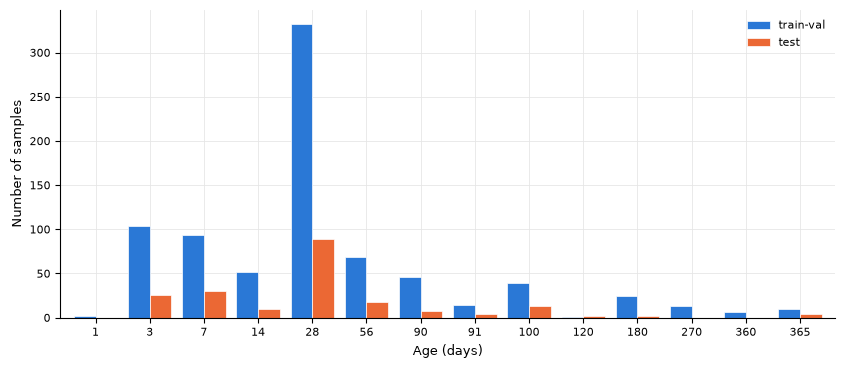

**Figura 1.** Número de muestras en cada edad del concreto, en train-val y en prueba.

Distinct ages in train-val: 14
Test ages not present in train-val: none


In [8]:
# The age only takes a few discrete values: count the samples at each age
age_counts = (pd.DataFrame({"train-val": train_val_df["age"].value_counts(),
                            "test": test_df["age"].value_counts()})
              .fillna(0).astype(int).sort_index())

ax = age_counts.plot.bar(figsize=(10, 4), color=[COLOR_TRAIN, COLOR_TEST],
                         width=0.8, edgecolor="white", linewidth=0.5)
ax.set_xlabel(LABELS["age"])
ax.set_ylabel("Number of samples")
ax.tick_params(axis="x", rotation=0)
show_figure(ax.figure, 1, "Número de muestras en cada edad del concreto, en train-val y en prueba.")

print(f"Distinct ages in train-val: {train_val_df['age'].nunique()}")
print(f"Test ages not present in train-val: "
      f"{sorted(set(test_df['age']) - set(train_val_df['age'])) or 'none'}")

Observaciones de la Figura 1:

- La edad solo toma **14 valores distintos**, que corresponden a las edades de ensayo habituales en laboratorio (3, 7, 14, 28, 56, 90 días, etc.). Por eso puede tratarse como una variable numérica o como una variable categórica (one-hot), alternativa que se compara en la sección 8.2.
- La edad de **28 días**, que es la edad de referencia para especificar la resistencia del concreto, concentra cerca del 40 % de las muestras. Algunas edades tienen muy pocas muestras (1 día: 2 muestras; 120 días: 1 muestra).
- Todas las edades del conjunto de prueba aparecen en train-val, así que una codificación one-hot no encontraría categorías desconocidas al evaluar en prueba.

**Cobertura del conjunto de prueba: mezclas que también aparecen en train-val.** Para esta revisión solo se comparan las variables de entrada (mezcla y edad), sin mirar la resistencia del conjunto de prueba.

In [9]:
# Test samples whose inputs (mix and age) also appear in train-val
train_val_mixes = train_val_df[FEATURES].drop_duplicates()
test_seen_mix = (test_df[FEATURES]
                 .merge(train_val_mixes, how="left", indicator=True)["_merge"]
                 .eq("both")
                 .to_numpy())

print(f"Test samples with repeated inputs within test: {test_df.duplicated(subset=FEATURES).sum()}")
print(f"Test samples whose mix and age also appear in train-val: "
      f"{test_seen_mix.sum()} of {len(test_df)} ({test_seen_mix.mean():.1%})")

Test samples with repeated inputs within test: 1
Test samples whose mix and age also appear in train-val: 10 of 206 (4.9%)


El conjunto de prueba **no se modifica**: es el conjunto de referencia entregado con el enunciado para la evaluación final. La máscara `test_seen_mix` se guarda para reportar en la sección 9 el desempeño en prueba también sin estas muestras, y así comprobar que el resultado no está inflado porque el modelo ya conocía esas mezclas.

### 2.3 Detección de posibles outliers

Un outlier es un registro cuya resistencia medida se aparta mucho de lo que indican los demás registros con mezclas y edades parecidas, por ejemplo por un error de registro o un ensayo defectuoso. Para encontrarlos se entrena una red neuronal con el resto de los datos y se compara su predicción con la resistencia medida de cada registro. Para que esa comparación sea confiable, la red tiene que cumplir dos condiciones:

- **Error bajo:** si la red predice mal en general, los registros con error alto no se distinguen de los demás.
- **Poco overfitting:** una red que memoriza los datos de entrenamiento no aprende la relación general entre la mezcla, la edad y la resistencia, y sus errores en datos nuevos dependen de qué registros le tocaron.

Por eso, la sección tiene dos partes: primero se buscan los hiperparámetros de las redes que cumplen mejor ambas condiciones, y después se analizan los registros que esas redes predicen con más error.

**Validación cruzada.** La predicción de cada registro tiene que hacerla un modelo que **no lo vio** durante el entrenamiento. Para eso se usa la validación cruzada k-fold con $K = 10$: los 805 registros se reparten al azar en 10 folds de 80 u 81 registros, se entrena la red 10 veces con 9 folds (724 o 725 registros) y en cada vuelta se predice el fold que quedó fuera. Esto se repite $R = 5$ veces con las semillas 42 a 46; en cada repetición cambian los registros de cada fold y los pesos iniciales de la red, así que el resultado no depende de un reparto o de una inicialización en particular.

**Error y overfitting.** En cada fold $k$ de cada repetición $r$ se calcula el RMSE con la Ecuación (1), tanto en los registros de entrenamiento como en los de validación:

$$
\text{RMSE}_{rk} = \sqrt{\frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}_i - y_i\right)^2} \tag{1}
$$

donde $m$ es el número de registros del conjunto (724 o 725 en entrenamiento, 80 u 81 en validación), $y_i$ es la resistencia medida del registro $i$ y $\hat{y}_i$ es la predicción de la red entrenada en ese fold. El error de entrenamiento y el de validación de una red son los promedios de los $R \times K = 50$ entrenamientos (Ecuación 2), y el overfitting se mide con la brecha entre ambos (Ecuación 3):

$$
\overline{\text{RMSE}}_{\text{train}} = \frac{1}{RK}\sum_{r=1}^{R}\sum_{k=1}^{K}\text{RMSE}^{\text{train}}_{rk}, \qquad \overline{\text{RMSE}}_{\text{val}} = \frac{1}{RK}\sum_{r=1}^{R}\sum_{k=1}^{K}\text{RMSE}^{\text{val}}_{rk} \tag{2}
$$

$$
\Delta = \overline{\text{RMSE}}_{\text{val}} - \overline{\text{RMSE}}_{\text{train}} \tag{3}
$$

Una red con $\overline{\text{RMSE}}_{\text{val}}$ alto y $\Delta$ pequeño no alcanza a representar los datos (sesgo alto); una red con $\overline{\text{RMSE}}_{\text{train}}$ bajo y $\Delta$ grande los memoriza (overfitting o varianza alta). La red buscada tiene $\overline{\text{RMSE}}_{\text{val}}$ bajo y $\Delta$ pequeño.

**Búsqueda por etapas.** Los hiperparámetros no se prueban uno por uno, porque el mejor valor de uno puede depender de los otros (por ejemplo, el valor conveniente de la regularización depende del tamaño de la red). Tampoco se prueban todas las combinaciones, que serían 384. Se fija primero lo que no depende de los demás y se busca en conjunto lo que sí interactúa:

1. **Etapa 1:** la edad entra como $\ln(t)$.
2. **Etapa 2:** 8 arquitecturas × 2 funciones de activación = 16 redes, con la regularización por defecto.
3. **Etapa 3:** las 4 redes que se elijan en la etapa 2 × 3 valores de $\alpha$ × con y sin early stopping × 2 tasas de aprendizaje = 48 redes.

En todas las redes, las entradas se escalan con `StandardScaler` dentro de cada fold, el optimizador es Adam, el máximo es de 10 000 iteraciones y el entrenamiento se detiene cuando el error no mejora durante 50 iteraciones seguidas (`n_iter_no_change=50`). Con la paciencia por defecto de scikit-learn (10 iteraciones), en una prueba preliminar el entrenamiento con early stopping se detenía demasiado pronto y la red quedaba con sesgo alto.

#### Etapa 1: la edad como $\ln(t)$

La red recibe las entradas estandarizadas (media 0 y desviación estándar 1). Si la edad entra en días, como su distribución está muy cargada hacia las edades bajas, las primeras edades quedan casi en el mismo valor para la red, justo donde la resistencia crece más rápido; en cambio, las edades altas, donde la resistencia casi no cambia, quedan muy separadas. Con el logaritmo natural de la edad, $\ln(t)$ con $t$ en días, ocurre lo contrario. La Tabla 7 muestra los valores que recibe la red en cada caso.

In [10]:
# Value of each age after standardization (StandardScaler uses the population standard deviation)
ages = np.sort(train_val_df["age"].unique())
log_age = np.log(train_val_df["age"])
age_scaling = pd.DataFrame({
    "age (days)": ages,
    "standardized age": (ages - train_val_df["age"].mean()) / train_val_df["age"].std(ddof=0),
    "standardized ln(age)": (np.log(ages) - log_age.mean()) / log_age.std(ddof=0),
})
show_table(age_scaling, 7,
           "Valor que recibe la red para cada edad de los registros de train-val, después de estandarizar la "
           "edad en días o su logaritmo natural.", hide_index=True)

**Tabla 7.** Valor que recibe la red para cada edad de los registros de train-val, después de estandarizar la edad en días o su logaritmo natural.

age (days),standardized age,standardized ln(age)
1,-0.71,-2.65
3,-0.68,-1.73
7,-0.61,-1.03
14,-0.51,-0.45
28,-0.29,0.12
56,0.14,0.70
90,0.66,1.10
91,0.67,1.10
100,0.81,1.18
120,1.12,1.33


Con la edad en días, 1, 3 y 7 días quedan en −0.71, −0.68 y −0.61: para la red son casi la misma entrada, aunque la resistencia se duplica o triplica en ese intervalo. Entre 90 y 365 días hay, en cambio, más de 4 unidades. Con $\ln(t)$, las edades tempranas quedan bien separadas y las tardías se acercan, que es la forma de la curva de curado del concreto.

**Decisión:** la edad entra como $\ln(t)$ en todas las redes de la búsqueda, por tres razones:

- Separa las edades tempranas (Tabla 7).
- Yeh (1998) usa $\ln(t)$ en su regresión de la resistencia, y en este conjunto la correlación de la resistencia con $\ln(t)$ es 0.56, frente a 0.35 con la edad en días (Figura 6, sección 2.4).
- En una prueba preliminar con las redes de 1 capa de 8 neuronas y de 2 capas de 64 y 32 neuronas, con ReLU y con tanh, $\ln(t)$ bajó el RMSE de validación en las cuatro combinaciones: de 7.80 a 6.34 MPa, de 6.03 a 5.98 MPa, de 5.35 a 4.91 MPa y de 5.23 a 5.11 MPa. Como mejora todas las combinaciones, no hace falta incluirla en la búsqueda conjunta.

#### Etapa 2: arquitectura y función de activación

Se prueban 8 arquitecturas, desde 1 capa oculta de 8 neuronas (la de Yeh, 1998) hasta 3 capas ocultas de 64, 32 y 16 neuronas, cada una con las funciones de activación ReLU y tanh. La arquitectura se escribe con el número de neuronas de cada capa oculta entre paréntesis: (32, 16) son 2 capas ocultas con 32 y 16 neuronas. En esta etapa todas las redes usan la regularización L2 por defecto ($\alpha = 0.0001$), sin early stopping, y una tasa de aprendizaje de 0.001.

La Tabla 8 resume las 16 redes, ordenadas por $\overline{\text{RMSE}}_{\text{val}}$, y la Figura 2 las ubica según su error de validación y su brecha. Una red está en el **frente de Pareto** si ninguna otra la supera a la vez en error de validación y en brecha; las redes fuera del frente tienen al menos otra red que es mejor o igual en ambos criterios.

Entrenar todas las redes de la búsqueda toma unos 35 minutos, así que los resultados se guardan en un archivo de caché (`cache/question-1-hyperparameter-search.joblib`, fuera de git). En las ejecuciones siguientes se leen de ese archivo; si cambian los datos o la configuración de una red, esa red se vuelve a entrenar.

**Tabla 8.** Resultados de la etapa 2, ordenados por error de validación: RMSE de entrenamiento y de validación (MPa, promedio de 50 entrenamientos, Ecuación 2), brecha (Ecuación 3), desviación estándar del RMSE de validación entre las 5 repeticiones, mediana del número de iteraciones y si la red está en el frente de Pareto.

,,train RMSE,validation RMSE,gap,validation std (repetitions),iterations (median),Pareto front
architecture,activation,,,,,,
"(64, 32)",relu,1.60,4.97,3.37,0.13,3873.00,yes
"(32,)",relu,3.47,5.10,1.63,0.07,10000.00,yes
"(64, 32, 16)",relu,1.69,5.22,3.53,0.25,2484.50,no
"(32, 16)",relu,2.44,5.25,2.81,0.20,6027.50,no
"(64, 32)",tanh,1.07,5.26,4.19,0.12,5389.00,no
"(16, 8)",relu,3.58,5.34,1.76,0.14,6690.00,no
"(32, 16, 8)",relu,2.21,5.43,3.23,0.16,4194.00,no
"(32,)",tanh,2.87,5.43,2.56,0.18,10000.00,no
"(16,)",tanh,3.96,5.55,1.59,0.11,10000.00,yes


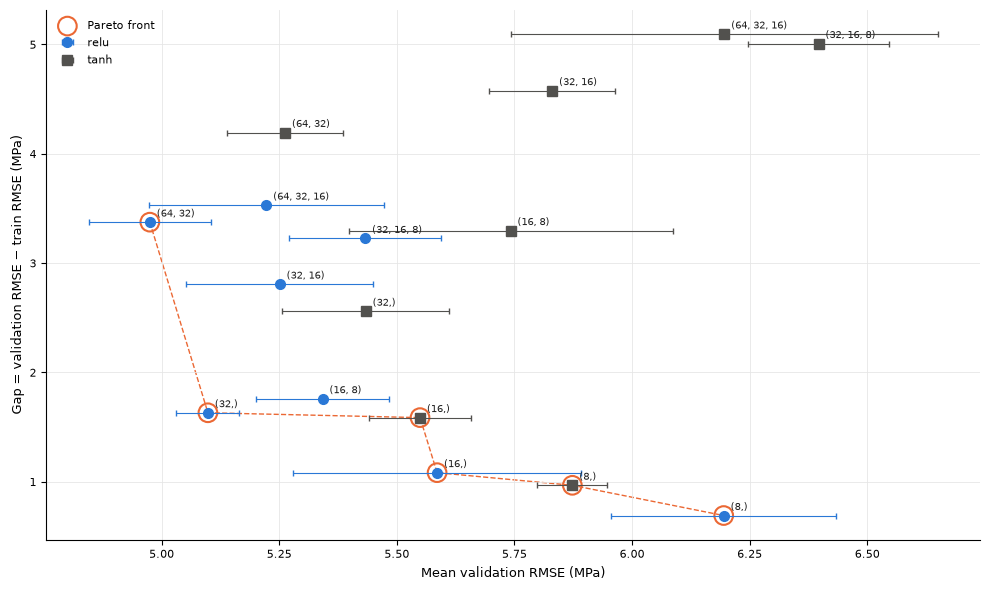

**Figura 2.** Error de validación y brecha de las 16 redes de la etapa 2. Círculos azules: ReLU; cuadrados grises: tanh; la etiqueta es la arquitectura. La barra horizontal es la desviación estándar del RMSE de validación entre las 5 repeticiones. Los anillos naranjas, unidos por la línea discontinua, marcan el frente de Pareto. La mejor red estaría en la esquina inferior izquierda: poco error y poca brecha.

In [11]:
# Inputs of the search: the age enters as its natural logarithm (stage 1)
X_search = train_val_df[FEATURES].assign(age=np.log(train_val_df["age"]))
y_search = train_val_df[TARGET]
REPEAT_SEEDS = [SEED + r for r in range(5)]   # 42 to 46: new folds and new initial weights each time
COMMON_PARAMS = dict(solver="adam", n_iter_no_change=50, max_iter=10_000)


# Cache of the search results: training every network takes about 35 minutes. A result is reused only if the
# data, the network settings, the seeds and the number of folds are the same; otherwise it is recomputed.
SEARCH_CACHE = Path("cache") / "question-1-hyperparameter-search.joblib"
search_cache = joblib.load(SEARCH_CACHE) if SEARCH_CACHE.exists() else {}
DATA_HASH = int(pd.util.hash_pandas_object(pd.concat([X_search, y_search], axis=1)).sum())


def evaluate_network(params):
    """Cached result of cross_validate_network (see SEARCH_CACHE)."""
    cache_key = repr((DATA_HASH, REPEAT_SEEDS, N_FOLDS, sorted({**COMMON_PARAMS, **params}.items())))
    if cache_key not in search_cache:
        search_cache[cache_key] = cross_validate_network(params)
        SEARCH_CACHE.parent.mkdir(exist_ok=True)
        joblib.dump(search_cache, SEARCH_CACHE)
    return search_cache[cache_key]


def cross_validate_network(params):
    """Repeated k-fold of one network: train and validation RMSE of every fold, and out-of-fold predictions."""
    fold_rows = []
    oof = pd.DataFrame(index=y_search.index, columns=REPEAT_SEEDS, dtype=float)
    for seed in REPEAT_SEEDS:
        model = make_pipeline(StandardScaler(), MLPRegressor(random_state=seed, **COMMON_PARAMS, **params))
        folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        cv = cross_validate(model, X_search, y_search, cv=folds, scoring="neg_root_mean_squared_error",
                            return_train_score=True, return_estimator=True, return_indices=True, n_jobs=-1)
        predictions = np.empty(len(y_search))
        for estimator, val_idx in zip(cv["estimator"], cv["indices"]["test"]):
            predictions[val_idx] = estimator.predict(X_search.iloc[val_idx])
        oof[seed] = predictions
        fold_rows += [{"seed": seed, "train": -train, "validation": -val, "iterations": estimator[-1].n_iter_}
                      for train, val, estimator in zip(cv["train_score"], cv["test_score"], cv["estimator"])]
    return pd.DataFrame(fold_rows), oof


def summarize(folds):
    """Mean train and validation RMSE (Equation 2), gap (Equation 3) and spread between repetitions."""
    return {"train RMSE": folds["train"].mean(),
            "validation RMSE": folds["validation"].mean(),
            "gap": folds["validation"].mean() - folds["train"].mean(),
            "validation std (repetitions)": folds.groupby("seed")["validation"].mean().std(),
            "iterations (median)": folds["iterations"].median()}


def pareto_front(summary):
    """True for the networks that no other network beats in both validation RMSE and gap."""
    val, gap = summary["validation RMSE"].to_numpy(), summary["gap"].to_numpy()
    return ["yes" if not np.any((val <= v) & (gap <= g) & ((val < v) | (gap < g))) else "no"
            for v, g in zip(val, gap)]


# Stage 2: every architecture with every activation, default regularization
ARCHITECTURES = [(8,), (16,), (32,), (16, 8), (32, 16), (64, 32), (32, 16, 8), (64, 32, 16)]
ACTIVATIONS = ["relu", "tanh"]
STAGE_2_PARAMS = dict(alpha=0.0001, early_stopping=False, learning_rate_init=0.001)

# Results of every network, by (architecture, activation, alpha, early stopping, learning rate)
search_folds, search_oof = {}, {}
stage_2_rows = []
for architecture in ARCHITECTURES:
    for activation in ACTIVATIONS:
        key = (str(architecture), activation, *STAGE_2_PARAMS.values())
        search_folds[key], search_oof[key] = evaluate_network(
            dict(STAGE_2_PARAMS, hidden_layer_sizes=architecture, activation=activation))
        stage_2_rows.append({"architecture": str(architecture), "activation": activation,
                             **summarize(search_folds[key])})

stage_2 = pd.DataFrame(stage_2_rows).set_index(["architecture", "activation"]).sort_values("validation RMSE")
stage_2["Pareto front"] = pareto_front(stage_2)
show_table(stage_2, 8,
           "Resultados de la etapa 2, ordenados por error de validación: RMSE de entrenamiento y de validación "
           "(MPa, promedio de 50 entrenamientos, Ecuación 2), brecha (Ecuación 3), desviación estándar del "
           "RMSE de validación entre las 5 repeticiones, mediana del número de iteraciones y si la red está en "
           "el frente de Pareto.")

# Figure 2: validation error vs gap
ACTIVATION_STYLE = {"relu": dict(marker="o", color=COLOR_TRAIN), "tanh": dict(marker="s", color=COLOR_MUTED)}
fig, ax = plt.subplots(figsize=(10, 6))
for activation, style in ACTIVATION_STYLE.items():
    rows = stage_2.xs(activation, level="activation")
    ax.errorbar(rows["validation RMSE"], rows["gap"], xerr=rows["validation std (repetitions)"],
                linestyle="none", markersize=7, elinewidth=0.8, capsize=2, label=activation, **style)
    for architecture, row in rows.iterrows():
        ax.annotate(architecture, (row["validation RMSE"], row["gap"]), xytext=(5, 4),
                    textcoords="offset points", fontsize=7.5, color="#1f1f1f")
front = stage_2[stage_2["Pareto front"] == "yes"].sort_values("validation RMSE")
ax.plot(front["validation RMSE"], front["gap"], "--", color=COLOR_TEST, linewidth=1, zorder=0)
ax.scatter(front["validation RMSE"], front["gap"], s=180, facecolors="none", edgecolors=COLOR_TEST,
           linewidths=1.5, label="Pareto front")
ax.set_xlabel("Mean validation RMSE (MPa)")
ax.set_ylabel("Gap = validation RMSE − train RMSE (MPa)")
ax.legend(loc="upper left")
fig.tight_layout()
show_figure(fig, 2,
            "Error de validación y brecha de las 16 redes de la etapa 2. Círculos azules: ReLU; cuadrados "
            "grises: tanh; la etiqueta es la arquitectura. La barra horizontal es la desviación estándar del "
            "RMSE de validación entre las 5 repeticiones. Los anillos naranjas, unidos por la línea discontinua, "
            "marcan el frente de Pareto. La mejor red estaría en la esquina inferior izquierda: poco error y poca "
            "brecha.")

Observaciones de la Tabla 8 y la Figura 2:

- **Las redes grandes aprenden más, pero memorizan.** Salvo (16, 8) con ReLU, las redes de 2 y 3 capas tienen el error de entrenamiento más bajo (de 1.07 a 2.44 MPa) y brechas de 2.8 a 5.1 MPa: hay overfitting. La de menor error de validación, (64, 32) con ReLU (4.97 MPa), tiene un error de entrenamiento de solo 1.60 MPa y una brecha de 3.37 MPa.
- **Las redes pequeñas no memorizan, pero se quedan cortas.** Las redes (8,) y (16,) tienen las brechas más pequeñas (de 0.69 a 1.59 MPa), pero su error de validación es de 5.55 a 6.19 MPa, y su error de entrenamiento también es alto (de 3.96 a 5.50 MPa): les falta capacidad (sesgo alto).
- **tanh hace más overfitting que ReLU en las redes de varias capas.** Con la misma arquitectura, la brecha con tanh es mayor: 4.19 frente a 3.37 MPa en (64, 32), 4.58 frente a 2.81 MPa en (32, 16) y 5.10 frente a 3.53 MPa en (64, 32, 16). Las dos redes de 3 capas con tanh tienen el mayor error de validación (6.20 y 6.40 MPa). En las redes de 1 capa no hay una diferencia clara: tanh es mejor en (8,), igual en (16,) y peor en (32,).
- **Frente de Pareto:** 6 redes, (64, 32) y (32,) con ReLU, (16,) y (8,) con ReLU y con tanh. La red (32,) con ReLU es el mejor equilibrio: su error de validación (5.10 MPa) es solo 0.13 MPa mayor que el de la mejor red, con la mitad de la brecha (1.63 MPa).
- **Las diferencias pequeñas no son significativas.** La desviación estándar del error de validación entre repeticiones va de 0.07 a 0.45 MPa, así que diferencias de 0.1 a 0.2 MPa entre redes pueden deberse al reparto de los folds y a los pesos iniciales.
- **Varias redes llegaron al máximo de 10 000 iteraciones** (mediana de 10 000 en la Tabla 8): las de 1 capa (salvo (8,) con ReLU) y (16, 8) con tanh. Con una tasa de aprendizaje de 0.001 avanzan despacio y el criterio de parada no alcanzó a detenerlas. La etapa 3 prueba también una tasa de 0.01.

**Redes elegidas para la etapa 3.** La regularización y el early stopping reducen la brecha, a cambio de que la red aprenda una función más simple. Sirven, por lo tanto, para las redes con poco error de validación y brecha grande, y no para las que ya tienen sesgo alto, como (8,) y (16,): a estas, regularizarlas les subiría todavía más el error. Por eso se eligen 4 de las redes con menor error de validación, que cubren 1, 2 y 3 capas y ambas funciones de activación:

1. **(64, 32) con ReLU:** el menor error de validación (4.97 MPa), con una brecha grande que la regularización puede reducir.
2. **(32,) con ReLU:** el mejor equilibrio del frente de Pareto.
3. **(64, 32, 16) con ReLU:** la mejor red de 3 capas (5.22 MPa).
4. **(64, 32) con tanh:** la mejor red con tanh (5.26 MPa), con la brecha más grande de las cuatro (4.19 MPa).

La red (32, 16) con ReLU (5.25 MPa) queda fuera porque su error es prácticamente igual al de (64, 32, 16) y (64, 32) con tanh, y su arquitectura está entre (32,) y (64, 32), que ya están incluidas.

#### Etapa 3: regularización y tasa de aprendizaje

Las 4 redes elegidas en la etapa 2 se combinan con tres formas de controlar el overfitting y con la tasa de aprendizaje, que interactúa con ellas:

- **Regularización L2**, $\alpha = 0.0001$ (el valor por defecto), 0.01 y 1. El término $\alpha$ penaliza los pesos grandes en la función de costo; cuanto mayor es, más simple es la función que aprende la red.
- **Early stopping**, sí o no. Con early stopping, scikit-learn aparta el 10 % de los datos de entrenamiento de cada fold y detiene el entrenamiento cuando el error en ese 10 % deja de mejorar durante 50 iteraciones seguidas.
- **Tasa de aprendizaje**, 0.001 y 0.01. Con una tasa mayor, la red avanza más en cada iteración, lo que cambia en qué momento se detiene el entrenamiento.

Son 4 × 3 × 2 × 2 = 48 redes; las 4 con $\alpha = 0.0001$, sin early stopping y con tasa de 0.001 son las mismas de la etapa 2 y no se vuelven a entrenar. La Tabla 9 resume las 48 redes, ordenadas por $\overline{\text{RMSE}}_{\text{val}}$, y la Figura 3 las ubica según su error de validación y su brecha, con un panel por red.

**Tabla 9.** Resultados de la etapa 3, ordenados por error de validación: RMSE de entrenamiento y de validación (MPa, promedio de 50 entrenamientos, Ecuación 2), brecha (Ecuación 3), desviación estándar del RMSE de validación entre las 5 repeticiones, mediana del número de iteraciones y si la red está en el frente de Pareto de las 48 redes.

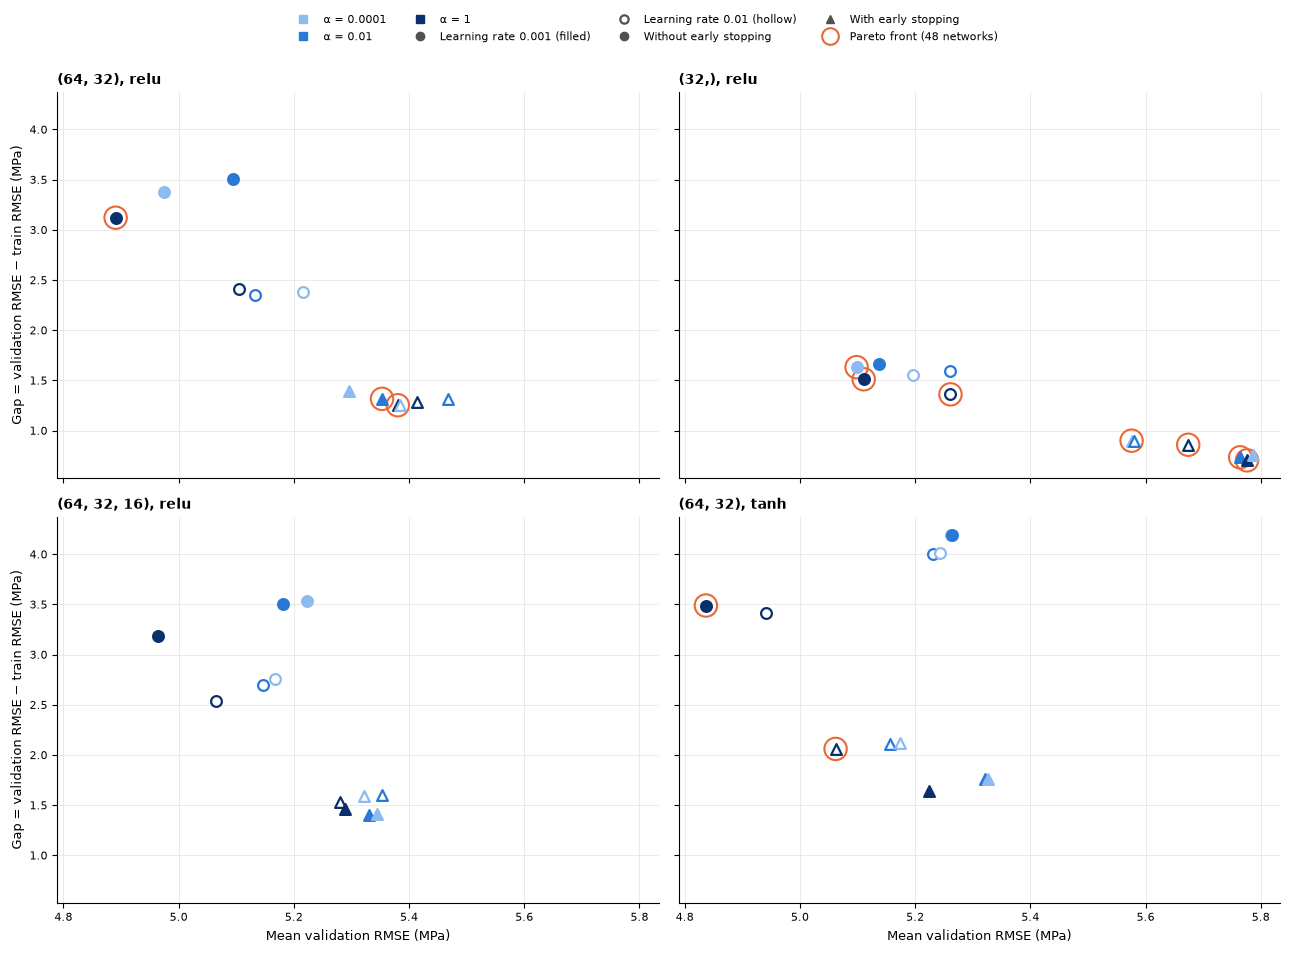

**Figura 3.** Error de validación y brecha de las 48 redes de la etapa 3, con un panel por cada red elegida en la etapa 2. Color: valor de α (más oscuro, más regularización); relleno: tasa de aprendizaje (lleno 0.001, vacío 0.01); forma: sin early stopping (círculo) o con early stopping (triángulo). El anillo naranja marca las redes del frente de Pareto de las 48. La mejor red estaría en la esquina inferior izquierda: poco error y poca brecha.

In [12]:
# Stage 3: the networks chosen in stage 2, with every regularization and learning rate
STAGE_3_NETWORKS = [
    ("(64, 32)", "relu"),
    ("(32,)", "relu"),
    ("(64, 32, 16)", "relu"),
    ("(64, 32)", "tanh"),
]
ALPHAS = [0.0001, 0.01, 1.0]
EARLY_STOPPING = [False, True]
LEARNING_RATES = [0.001, 0.01]
ARCHITECTURE_BY_NAME = {str(a): a for a in ARCHITECTURES}

stage_3_rows = []
for architecture, activation in STAGE_3_NETWORKS:
    for alpha in ALPHAS:
        for early_stopping in EARLY_STOPPING:
            for learning_rate in LEARNING_RATES:
                key = (architecture, activation, alpha, early_stopping, learning_rate)
                if key not in search_folds:   # the stage-2 combination is already trained
                    search_folds[key], search_oof[key] = evaluate_network(dict(
                        hidden_layer_sizes=ARCHITECTURE_BY_NAME[architecture], activation=activation, alpha=alpha,
                        early_stopping=early_stopping, learning_rate_init=learning_rate))
                stage_3_rows.append({"architecture": architecture, "activation": activation, "alpha": f"{alpha:g}",
                                     "early stopping": "yes" if early_stopping else "no",
                                     "learning rate": f"{learning_rate:g}", **summarize(search_folds[key])})

stage_3 = (pd.DataFrame(stage_3_rows)
           .set_index(["architecture", "activation", "alpha", "early stopping", "learning rate"])
           .sort_values("validation RMSE"))
stage_3["Pareto front"] = pareto_front(stage_3)
show_table(stage_3, 9,
           "Resultados de la etapa 3, ordenados por error de validación: RMSE de entrenamiento y de validación "
           "(MPa, promedio de 50 entrenamientos, Ecuación 2), brecha (Ecuación 3), desviación estándar del "
           "RMSE de validación entre las 5 repeticiones, mediana del número de iteraciones y si la red está en "
           "el frente de Pareto de las 48 redes.")

# Figure 3: validation error vs gap, one panel per network of stage 2
ALPHA_COLOR = {"0.0001": "#8dbbf0", "0.01": "#2a78d6", "1": "#0b2f6b"}   # darker = stronger L2 penalty
ES_MARKER = {"no": "o", "yes": "^"}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
for ax, (architecture, activation) in zip(axes.flat, STAGE_3_NETWORKS):
    rows = stage_3.xs((architecture, activation), level=["architecture", "activation"])
    for (alpha, early_stopping, learning_rate), row in rows.iterrows():
        color = ALPHA_COLOR[alpha]
        # Filled marker: learning rate 0.001; hollow marker: 0.01
        ax.scatter(row["validation RMSE"], row["gap"], s=60, marker=ES_MARKER[early_stopping],
                   facecolors=color if learning_rate == "0.001" else "white", edgecolors=color,
                   linewidths=1.6, zorder=3)
        if row["Pareto front"] == "yes":
            ax.scatter(row["validation RMSE"], row["gap"], s=260, facecolors="none", edgecolors=COLOR_TEST,
                       linewidths=1.5, zorder=2)
    ax.set_title(f"{architecture}, {activation}", loc="left", fontweight="bold")
for ax in axes[-1]:
    ax.set_xlabel("Mean validation RMSE (MPa)")
for ax in axes[:, 0]:
    ax.set_ylabel("Gap = validation RMSE − train RMSE (MPa)")
legend_handles = (
    [plt.Line2D([], [], marker="s", linestyle="none", color=c, label=f"α = {a}") for a, c in ALPHA_COLOR.items()]
    + [plt.Line2D([], [], marker="o", linestyle="none", color=COLOR_MUTED, label="Learning rate 0.001 (filled)"),
       plt.Line2D([], [], marker="o", linestyle="none", markerfacecolor="white", markeredgecolor=COLOR_MUTED,
                  markeredgewidth=1.6, label="Learning rate 0.01 (hollow)"),
       plt.Line2D([], [], marker="o", linestyle="none", color=COLOR_MUTED, label="Without early stopping"),
       plt.Line2D([], [], marker="^", linestyle="none", color=COLOR_MUTED, label="With early stopping"),
       plt.Line2D([], [], marker="o", linestyle="none", markersize=12, markerfacecolor="none",
                  markeredgecolor=COLOR_TEST, markeredgewidth=1.5, label="Pareto front (48 networks)")])
fig.legend(handles=legend_handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
show_figure(fig, 3,
            "Error de validación y brecha de las 48 redes de la etapa 3, con un panel por cada red elegida en la "
            "etapa 2. Color: valor de α (más oscuro, más regularización); relleno: tasa de aprendizaje (lleno "
            "0.001, vacío 0.01); forma: sin early stopping (círculo) o con early stopping (triángulo). El anillo "
            "naranja marca las redes del frente de Pareto de las 48. La mejor red estaría en la esquina inferior "
            "izquierda: poco error y poca brecha.")

Observaciones de la Tabla 9 y la Figura 3:

- **De los valores de $\alpha$ probados, solo $\alpha = 1$ cambia el resultado.** Con $\alpha = 0.01$ los resultados son casi iguales que con 0.0001 (diferencias de 0.12 MPa o menos, dentro de la variación entre repeticiones). Con $\alpha = 1$, sin early stopping y con tasa de 0.001, baja el error de validación de las tres redes grandes: (64, 32) con tanh, de 5.26 a 4.84 MPa; (64, 32, 16) con ReLU, de 5.22 a 4.96 MPa; y (64, 32) con ReLU, de 4.97 a 4.89 MPa. La brecha, en cambio, baja poco (queda entre 3.1 y 3.5 MPa). Como el mejor valor está en el extremo de los probados, un $\alpha$ mayor podría mejorar todavía más; por eso se amplía la búsqueda de $\alpha$ a continuación.
- **Early stopping reduce mucho la brecha, pero sube el error de validación.** Con early stopping la brecha baja a valores entre 0.7 y 2.1 MPa, pero el error de validación sube a valores entre 5.06 y 5.79 MPa: la red se detiene antes de aprender todo lo que puede y, además, entrena con un 10 % menos de datos. La mejor de estas redes es (64, 32) con tanh, $\alpha = 1$ y tasa de 0.01 (5.06 MPa, brecha de 2.06 MPa).
- **Con tasa de 0.01 y sin early stopping, el entrenamiento termina mucho antes**: entre 550 y 1 800 iteraciones, frente a entre 2 300 y 10 000 con tasa de 0.001. En las redes de 2 y 3 capas con ReLU, la brecha baja de 3.1–3.5 a 2.4–2.8 MPa, con un error de validación parecido o algo mayor. La red (32,) ya no llega al máximo de 10 000 iteraciones.
- **No hay una red con el menor error y la menor brecha a la vez.** El frente de Pareto tiene 12 redes y va de (64, 32) con tanh y $\alpha = 1$ (4.84 MPa, brecha de 3.49 MPa) a (32,) con ReLU y early stopping (5.78 MPa, brecha de 0.70 MPa): para bajar la brecha hay que aceptar más error de validación. En el medio, (32,) con ReLU, $\alpha = 1$ y tasa de 0.001 tiene 5.11 MPa con una brecha de 1.51 MPa: 0.27 MPa más de error que la mejor red, con menos de la mitad de su brecha.

**Ampliación de $\alpha$.** El mejor valor de $\alpha$ en la etapa 3 fue el más alto de los probados ($\alpha = 1$), así que no se sabe si un valor mayor sería todavía mejor. Se prueban $\alpha = 3$ y $\alpha = 10$ en las 4 redes, solo en la combinación donde $\alpha = 1$ ayudó: sin early stopping y con tasa de aprendizaje de 0.001. Son 8 redes nuevas. Como en (64, 32) y (64, 32, 16) con ReLU el error de validación seguía bajando en $\alpha = 10$, en esas dos redes se prueban además $\alpha = 30$ y $\alpha = 100$ (4 redes más). La Tabla 10 y la Figura 4 muestran cómo cambian el error de validación y la brecha con $\alpha$; el frente de Pareto de la Tabla 10 se calcula ahora con las 60 redes de la etapa 3 y de esta ampliación.

**Tabla 10.** Efecto de α en las 4 redes de la etapa 3, sin early stopping y con tasa de aprendizaje de 0.001: RMSE de entrenamiento y de validación (MPa, Ecuación 2), brecha (Ecuación 3), desviación estándar del RMSE de validación entre las 5 repeticiones, mediana del número de iteraciones y si la red está en el frente de Pareto de las 60 redes.

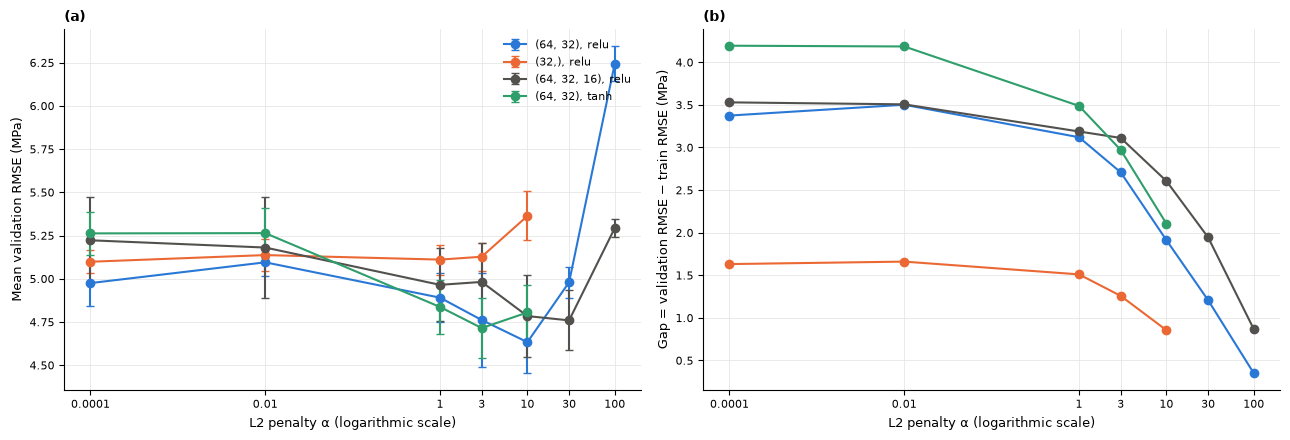

**Figura 4.** Efecto de la penalización L2 (α) en las 4 redes de la etapa 3, sin early stopping y con tasa de aprendizaje de 0.001: (a) error de validación, con barras de ± una desviación estándar entre las 5 repeticiones; (b) brecha entre el error de validación y el de entrenamiento.

In [13]:
# Stage 3, extension: larger L2 penalties, where alpha = 1 lowered the validation error
EXTRA_ALPHAS = [3.0, 10.0]
# Second extension: the two networks whose validation error was still decreasing at alpha = 10
LARGER_ALPHAS = {("(64, 32)", "relu"): [30.0, 100.0], ("(64, 32, 16)", "relu"): [30.0, 100.0]}
alpha_rows = []
for architecture, activation in STAGE_3_NETWORKS:
    for alpha in ALPHAS + EXTRA_ALPHAS + LARGER_ALPHAS.get((architecture, activation), []):
        key = (architecture, activation, alpha, False, 0.001)
        if key not in search_folds:
            search_folds[key], search_oof[key] = evaluate_network(dict(
                hidden_layer_sizes=ARCHITECTURE_BY_NAME[architecture], activation=activation, alpha=alpha,
                early_stopping=False, learning_rate_init=0.001))
        alpha_rows.append({"architecture": architecture, "activation": activation, "alpha": f"{alpha:g}",
                           "early stopping": "no", "learning rate": "0.001", **summarize(search_folds[key])})

# Pareto front of the 60 networks: stage 3 plus the extension
alpha_sweep = pd.DataFrame(alpha_rows).set_index(stage_3.index.names)
extension = alpha_sweep[~alpha_sweep.index.get_level_values("alpha").isin([f"{a:g}" for a in ALPHAS])]
all_networks = pd.concat([stage_3.drop(columns="Pareto front"), extension]).sort_values("validation RMSE")
all_networks["Pareto front"] = pareto_front(all_networks)

alpha_table = all_networks.loc[alpha_sweep.index].droplevel(["early stopping", "learning rate"])
show_table(alpha_table, 10,
           "Efecto de α en las 4 redes de la etapa 3, sin early stopping y con tasa de aprendizaje de 0.001: RMSE "
           "de entrenamiento y de validación (MPa, Ecuación 2), brecha (Ecuación 3), desviación estándar del RMSE "
           "de validación entre las 5 repeticiones, mediana del número de iteraciones y si la red está en el "
           "frente de Pareto de las 60 redes.")

# Figure 4: validation RMSE and gap vs alpha, one line per network
NETWORK_COLORS = [COLOR_TRAIN, COLOR_TEST, COLOR_MUTED, "#2e9e6b"]
alpha_values = sorted({float(a) for a in alpha_table.index.get_level_values("alpha")})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for (architecture, activation), color in zip(STAGE_3_NETWORKS, NETWORK_COLORS):
    rows = alpha_table.xs((architecture, activation), level=["architecture", "activation"])
    label = f"{architecture}, {activation}"
    alphas = rows.index.get_level_values("alpha").astype(float)
    axes[0].errorbar(alphas, rows["validation RMSE"], yerr=rows["validation std (repetitions)"], marker="o",
                     color=color, linewidth=1.5, capsize=3, label=label)
    axes[1].plot(alphas, rows["gap"], marker="o", color=color, linewidth=1.5, label=label)
for ax, ylabel, panel in zip(axes, ["Mean validation RMSE (MPa)", "Gap = validation RMSE − train RMSE (MPa)"],
                             ["(a)", "(b)"]):
    ax.set_xscale("log")
    ax.set_xticks(alpha_values)
    ax.set_xticklabels([f"{a:g}" for a in alpha_values])
    ax.minorticks_off()
    ax.set_xlabel("L2 penalty α (logarithmic scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(panel, loc="left", fontweight="bold")
axes[0].legend(loc="upper right")
fig.tight_layout()
show_figure(fig, 4,
            "Efecto de la penalización L2 (α) en las 4 redes de la etapa 3, sin early stopping y con tasa de "
            "aprendizaje de 0.001: (a) error de validación, con barras de ± una desviación estándar entre las 5 "
            "repeticiones; (b) brecha entre el error de validación y el de entrenamiento.")

Observaciones de la Tabla 10 y la Figura 4:

- **Cada red tiene un valor de $\alpha$ con el menor error de validación, y ahora está dentro de los valores probados:** $\alpha = 10$ en (64, 32) con ReLU (4.63 MPa), $\alpha = 30$ en (64, 32, 16) con ReLU (4.76 MPa) y $\alpha = 3$ en (64, 32) con tanh (4.71 MPa). En (32,) con ReLU el error casi no cambia entre $\alpha = 0.0001$ y $\alpha = 3$ (de 5.10 a 5.14 MPa) y sube con $\alpha = 10$.
- **La brecha baja siempre al aumentar $\alpha$** (Figura 4b), pero pasado el mejor valor el error de validación sube rápido: la red pasa de memorizar a quedarse corta. El caso extremo es (64, 32) con ReLU y $\alpha = 100$: brecha de solo 0.35 MPa, pero error de entrenamiento de 5.89 MPa y de validación de 6.24 MPa (sesgo alto).
- **Con el $\alpha$ adecuado, la regularización baja el error y la brecha a la vez.** La red (64, 32) con ReLU y $\alpha = 10$ tiene el menor error de validación de toda la búsqueda (4.63 MPa) y su brecha bajó de 3.37 MPa (sin regularización, Tabla 8) a 1.91 MPa.
- **Las tres mejores redes están empatadas en la práctica:** 4.63, 4.71 y 4.76 MPa, con desviaciones estándar entre repeticiones de 0.17 y 0.18 MPa.
- **Frente de Pareto de las 60 redes (7 redes):** (64, 32) con ReLU y $\alpha = 10$ (4.63 MPa, brecha de 1.91 MPa), $\alpha = 30$ (4.98 MPa, 1.21 MPa) y $\alpha = 100$ (6.24 MPa, 0.35 MPa); (64, 32, 16) con ReLU y $\alpha = 100$ (5.29 MPa, 0.87 MPa); (32,) con ReLU y $\alpha = 10$ (5.36 MPa, 0.86 MPa); y dos redes (32,) con ReLU y early stopping (5.76 y 5.78 MPa, 0.73 y 0.70 MPa).

> *Pendiente: elegir las redes que se usarán para analizar los registros con error alto.*

### 2.4 Relación entre variables

Todas las figuras de esta sección usan el conjunto train-val sin duplicados (805 registros).

**Correlación entre variables**

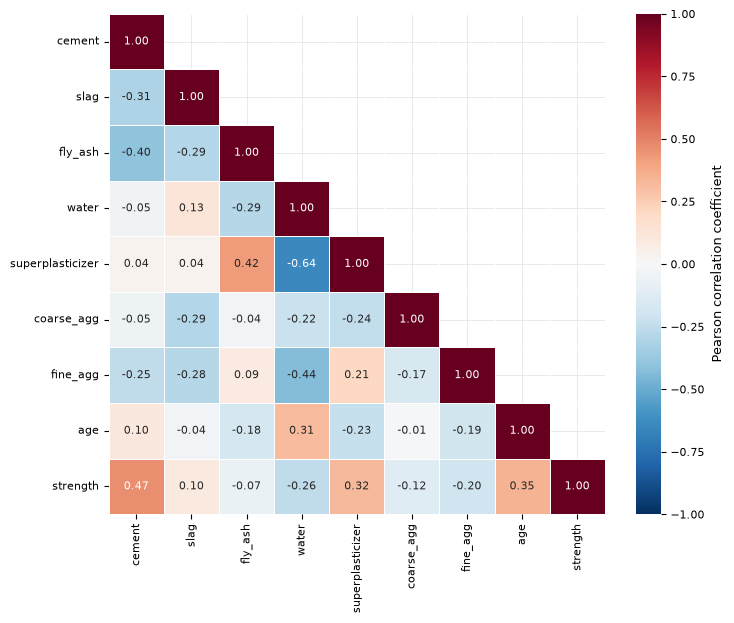

**Figura 5.** Coeficientes de correlación de Pearson entre las variables de train-val.

In [14]:
correlation = train_val_df.corr(method="pearson")
upper_triangle = np.triu(np.ones_like(correlation, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlation, mask=upper_triangle, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Pearson correlation coefficient"}, ax=ax)
show_figure(fig, 5, "Coeficientes de correlación de Pearson entre las variables de train-val.")

Los valores de la Figura 5 son coeficientes de correlación de Pearson. Para dos variables $x$ y $y$ se calculan con la Ecuación (4):

$$
r_{xy} = \frac{\sum_{i=1}^{m}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{m}(x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^{m}(y_i - \bar{y})^2}} \tag{4}
$$

donde $m$ es el número de muestras, $x_i$ y $y_i$ son los valores de la muestra $i$, y $\bar{x}$ y $\bar{y}$ son las medias. Toma valores entre $-1$ y $1$ y **solo mide relaciones lineales**.

Observaciones de la Figura 5:

- Ninguna variable explica por sí sola la resistencia. Las correlaciones más altas con la resistencia son las del cemento ($r = 0.47$), la edad ($0.35$) y el superplastificante ($0.32$), y la del agua es negativa ($-0.26$). Las demás son débiles.
- Que las correlaciones lineales sean moderadas no significa que las variables no influyan: la resistencia depende de **combinaciones** de componentes (por ejemplo, la relación agua/cemento) y de relaciones no lineales, como la de la edad. Esto justifica usar un modelo no lineal como una red neuronal.
- La correlación más fuerte entre entradas es la del agua con el superplastificante ($-0.64$): el superplastificante se usa justamente para reducir el agua necesaria sin perder trabajabilidad. Ninguna otra pareja de entradas tiene una correlación tan alta como para considerarla redundante.

**Resistencia vs. edad**

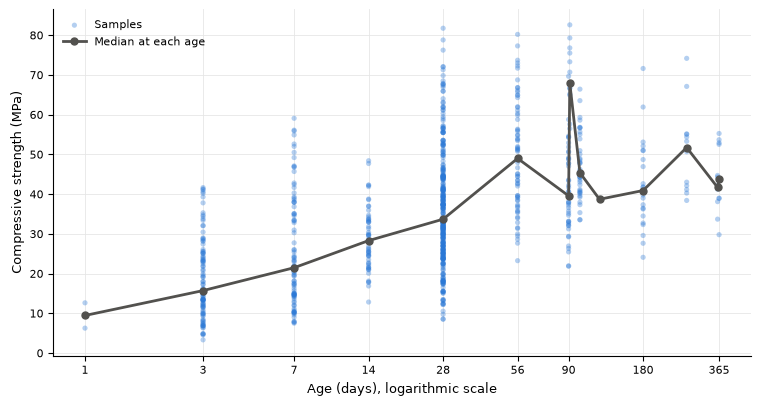

**Figura 6.** Resistencia a compresión vs. edad en train-val, con el eje horizontal en escala logarítmica. La línea gris une las medianas de cada edad.

Pearson r between strength and age:     0.35
Pearson r between strength and ln(age): 0.56


In [15]:
median_by_age = train_val_df.groupby("age")[TARGET].median()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(train_val_df["age"], train_val_df[TARGET], s=14, alpha=0.35,
           color=COLOR_TRAIN, edgecolors="none", label="Samples")
ax.plot(median_by_age.index, median_by_age.values, color=COLOR_MUTED, linewidth=2,
        marker="o", markersize=5, label="Median at each age")
ax.set_xscale("log")
# Label only a subset of ages so that close values (90/91/100, 360/365) do not overlap
AGE_TICKS = [1, 3, 7, 14, 28, 56, 90, 180, 365]
ax.set_xticks(AGE_TICKS)
ax.set_xticklabels(AGE_TICKS)
ax.minorticks_off()
ax.set_xlabel(LABELS["age"] + ", logarithmic scale")
ax.set_ylabel(LABELS[TARGET])
ax.legend(loc="upper left")
show_figure(fig, 6,
            "Resistencia a compresión vs. edad en train-val, con el eje horizontal en escala logarítmica. "
            "La línea gris une las medianas de cada edad.")

r_age = train_val_df["age"].corr(train_val_df[TARGET])
r_log_age = np.log(train_val_df["age"]).corr(train_val_df[TARGET])
print(f"Pearson r between strength and age:     {r_age:.2f}")
print(f"Pearson r between strength and ln(age): {r_log_age:.2f}")

Observaciones de la Figura 6:

- La resistencia crece rápido durante los primeros 28 días y después crece cada vez más lento, que es el comportamiento conocido del curado del concreto.
- En escala logarítmica la tendencia se parece más a una recta: la correlación con $\ln(\text{edad})$ ($r = 0.56$) es mayor que con la edad en días ($r = 0.35$). Esto coincide con la fórmula de regresión de Yeh (1998), que usa el término $\ln(t)$, y sugiere transformar la edad antes de entrenar la red (sección 8.2).
- Después de los 56 días la mediana sube y baja (por ejemplo, 67.9 MPa a los 91 días y 45.4 MPa a los 100 días). Esto no significa que el concreto pierda resistencia: cada edad incluye mezclas distintas, así que estas diferencias se deben a la dosificación y no a la edad.
- Para una misma edad la dispersión es grande (a los 28 días hay resistencias de menos de 10 MPa y de más de 80 MPa), lo que confirma que la edad por sí sola no basta para predecir la resistencia.

**Resistencia vs. relaciones agua/cemento y agua/aglomerante**

La ley de Abrams establece que la resistencia del concreto disminuye cuando aumenta la relación agua/cemento. Yeh (1998) muestra que, en concretos con escoria y ceniza volante, la relación agua/aglomerante predice mejor la resistencia. Ambas relaciones se definen con las Ecuaciones (5) y (6):

$$
\frac{w}{c} = \frac{W}{C} \tag{5}
$$

$$
\frac{w}{b} = \frac{W}{B} = \frac{W}{C + S + F} \tag{6}
$$

donde $W$ es la masa de agua, $C$ la de cemento, $S$ la de escoria de alto horno y $F$ la de ceniza volante, todas en kg por m³ de mezcla, y $B = C + S + F$ es la masa total de aglomerante. Aquí se calculan solo para graficarlas; su uso como variables de entrada se evalúa en la sección 8.1.

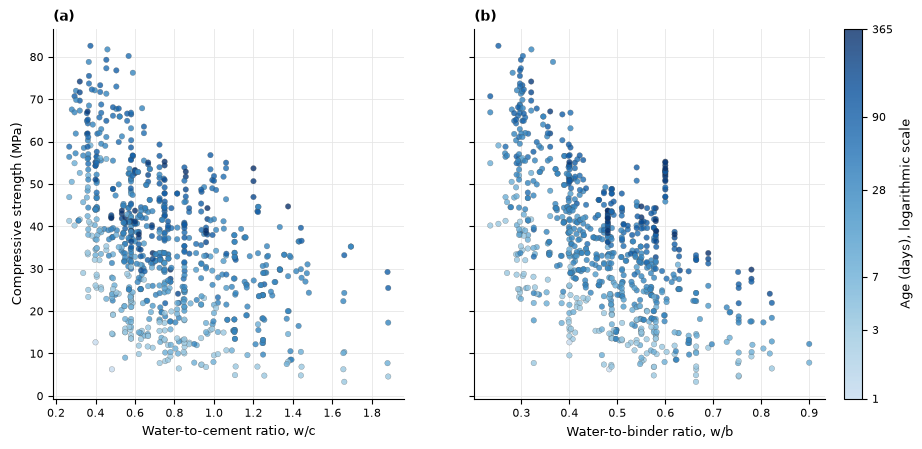

**Figura 7.** Resistencia a compresión vs. (a) relación agua/cemento y (b) relación agua/aglomerante, en train-val. El color indica la edad del concreto. Coeficiente de correlación de Pearson: (a) r = -0.47; (b) r = -0.59.

In [16]:
# Sequential blue scale without its near-white end, so that young samples stay visible
AGE_CMAP = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.25, 1.0, 256)))

binder = train_val_df["cement"] + train_val_df["slag"] + train_val_df["fly_ash"]
ratios = {
    "Water-to-cement ratio, w/c": train_val_df["water"] / train_val_df["cement"],
    "Water-to-binder ratio, w/b": train_val_df["water"] / binder,
}

r_ratios = {name: ratio.corr(train_val_df[TARGET]) for name, ratio in ratios.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, panel, (name, ratio) in zip(axes, ["(a)", "(b)"], ratios.items()):
    points = ax.scatter(ratio, train_val_df[TARGET], c=train_val_df["age"], cmap=AGE_CMAP,
                        norm=LogNorm(vmin=1, vmax=365), s=16, alpha=0.8,
                        edgecolors=COLOR_MUTED, linewidths=0.2)
    ax.set_xlabel(name)
    ax.set_title(panel, loc="left", fontweight="bold")
axes[0].set_ylabel(LABELS[TARGET])
colorbar = fig.colorbar(points, ax=axes, pad=0.02)
colorbar.set_ticks([1, 3, 7, 28, 90, 365])
colorbar.set_ticklabels(["1", "3", "7", "28", "90", "365"])
colorbar.minorticks_off()
colorbar.set_label(LABELS["age"] + ", logarithmic scale")
r_wc, r_wb = r_ratios.values()
show_figure(fig, 7,
            "Resistencia a compresión vs. (a) relación agua/cemento y (b) relación agua/aglomerante, "
            "en train-val. El color indica la edad del concreto. Coeficiente de correlación de Pearson: "
            f"(a) r = {r_wc:.2f}; (b) r = {r_wb:.2f}.")

Observaciones de la Figura 7:

- En ambas gráficas la resistencia disminuye cuando aumenta la relación, como predice la ley de Abrams.
- La relación agua/aglomerante tiene una correlación más fuerte con la resistencia ($r = -0.59$) que la relación agua/cemento ($r = -0.47$) y que cualquiera de las 8 variables originales (la mayor es la del cemento, $r = 0.47$). Esto coincide con lo que reporta Yeh (1998) y la convierte en una buena candidata como variable de entrada adicional (sección 8.1).
- Para una misma relación, buena parte de la dispersión vertical se explica por la edad: los puntos más oscuros (mayor edad) tienden a estar arriba. La red neuronal tendrá que combinar ambos efectos.

### 2.5 Observaciones del análisis exploratorio

> *Pendiente: conclusiones que guían el preprocesamiento y la ingeniería de variables.*

## 3. Métrica de evaluación

> *Pendiente: definición del RMSE (en LaTeX, con el significado de cada símbolo) y justificación de por qué es la métrica única para comparar modelos.*

## 4. Metodología de validación cruzada

> *Pendiente: explicación del k-fold, preprocesamiento dentro del `Pipeline` para evitar fuga de datos, función `evaluate` y tabla acumulada de experimentos, y criterio de diagnóstico de sesgo y varianza.*

## 5. Modelos de referencia

> *Pendiente: `DummyRegressor` (predice la media) y regresión lineal, como escala para juzgar los resultados de la red.*

## 6. Red neuronal base

> *Pendiente: arquitectura inicial (p. ej., 1 capa oculta de 8 neuronas, como Yeh), ecuaciones de propagación hacia adelante y función de costo, y resultado de validación cruzada.*

## 7. Diagnóstico de sesgo y varianza

### 7.1 Curva de aprendizaje

> *Pendiente: RMSE de entrenamiento y validación vs. número de muestras de entrenamiento.*

### 7.2 Curvas de validación

> *Pendiente: RMSE vs. número de neuronas y vs. parámetro de regularización $\alpha$.*

### 7.3 Curva de pérdida

> *Pendiente: evolución de la función de costo durante el entrenamiento para verificar la convergencia.*

### 7.4 Interpretación

> *Pendiente: diagnóstico del modelo base y estrategias a probar en la sección 8.*

## 8. Mejora del modelo

### 8.1 Nuevas variables de entrada

> *Pendiente: relaciones w/c, w/b, SP/b, escoria/b, ceniza/b y agregados/b.*

### 8.2 Tratamiento de la edad

> *Pendiente: edad cruda vs. $\ln(\text{edad})$ vs. one-hot de los 14 valores de edad.*

### 8.3 Escalado de entradas y salida

> *Pendiente: `StandardScaler` vs. `MinMaxScaler`, con y sin escalado de la resistencia.*

### 8.4 Arquitectura de la red

> *Pendiente: número de capas ocultas y de neuronas.*

### 8.5 Función de activación

> *Pendiente: `relu` vs. `tanh`.*

### 8.6 Optimizador y tasa de aprendizaje

> *Pendiente: `adam` vs. `sgd`, distintos valores de `learning_rate_init` y tasa adaptativa.*

### 8.7 Regularización

> *Pendiente: barrido de $\alpha$ (L2) y `early_stopping`.*

### 8.8 Búsqueda conjunta de hiperparámetros

> *Pendiente: `GridSearchCV` o `RandomizedSearchCV` con las mismas particiones k-fold.*

### 8.9 Resumen de experimentos

> *Pendiente: tabla de todos los experimentos ordenada por RMSE de validación cruzada y gráfica comparativa.*

## 9. Modelo final y evaluación en el conjunto de prueba

### 9.1 Entrenamiento del modelo final

> *Pendiente: reentrenamiento del mejor pipeline con todo train-val y su curva de aprendizaje.*

### 9.2 Desempeño en el conjunto de prueba

> *Pendiente: RMSE (y R², MAE como complemento) en prueba, comparado con el RMSE de validación cruzada; resultado también sin las filas repetidas entre train-val y test.*

### 9.3 Análisis de las predicciones

> *Pendiente: gráfico de paridad predicho vs. medido, residuos vs. predicción y vs. edad, y comparación con los resultados de Yeh (1998).*

## 10. Conclusiones

> *Pendiente: qué mejoró más el modelo, diagnóstico final de sesgo y varianza, limitaciones y trabajo futuro.*

## Referencias

- Yeh, I.C., 1998. Modeling of strength of high-performance concrete using artificial neural networks. *Cement and Concrete Research*, 28(12), pp. 1797-1808.